# Exercises on Autoencoders

## Exercise 1: Embedding space of an Autoencoder
This exercise aims to visualize the embedding space of a trained autoencoder on the FashionMNIST dataset. The goal is to understand how the autoencoder compresses and reconstructs the input data.

In [1]:
# get the FashionMNIST dataset
from torchvision import datasets
from torchvision.transforms import ToTensor
from torch.utils.data import DataLoader

training_data = datasets.FashionMNIST(
    root="data",
    train=True,
    download=True,
    transform=ToTensor()
)

test_data = datasets.FashionMNIST(
    root="data",
    train=False,
    download=True,
    transform=ToTensor()
)

# Training data for training the model, test data for embedding visualization
train_loader = DataLoader(training_data, batch_size=64, shuffle=True)
test_loader = DataLoader(test_data, batch_size=64, shuffle=False)

print(f"Training data size: {len(training_data)}")
print(f"Test data size: {len(test_data)}")

Training data size: 60000
Test data size: 10000


In [2]:
# Build a CNN Autoencoder model
# formula: 
#   Conv2d, [(in + 2*padding - kernel_size) / stride] + 1
#   ConvTranspose2d, (in-1)*s -2*padding + output_padding

import torch
import torch.nn as nn


# 這邊為什麼要設定 stride 是因為我們要達成縮小放大，如果只有1 那麼就不會縮小
# 原先圖形是28*28

class Autoencoder(torch.nn.Module):
    def __init__(self, latent_dim=16):
        super(Autoencoder, self).__init__()
        self.encoder = nn.Sequential(
            nn.Conv2d(1, 64, kernel_size=3, stride=2, padding=1),   # 1x28x28 -> 32x14x14, 這邊只有一個灰階
            nn.SiLU(),
            nn.Conv2d(64, 64, kernel_size=3, stride=2, padding=1),  # 32x14x14 -> 64x7x7
            nn.SiLU(),
            nn.Conv2d(64, 128, kernel_size=3, stride=2, padding=1), # 64x7x7 -> 128x4x4
            nn.SiLU(),
            nn.Flatten(),                                           # 128x4x4 -> 2048
            nn.Linear(128 * 4 * 4, latent_dim),                     # 2048 -> latent_dim (no activation)
        )
        
        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128 * 4 * 4),                     # latent_dim -> 2048
            nn.SiLU(),
            nn.Unflatten(1, (128, 4, 4)),                           # 2048 -> 128x4x4
            nn.ConvTranspose2d(128, 64, kernel_size=3, stride=2,
                               padding=1, output_padding=0),        # 128x4x4 -> 64x7x7
            nn.SiLU(),
            nn.ConvTranspose2d(64, 64, kernel_size=3, stride=2,
                               padding=1, output_padding=1),        # 64x7x7 -> 32x14x14
            nn.SiLU(),
            nn.ConvTranspose2d(64, 1, kernel_size=3, stride=2,
                               padding=1, output_padding=1),        # 32x14x14 -> 1x28x28
            nn.Sigmoid(),                                           # pixel values in [0, 1]
        )
        
    def forward(self, x):
        x = self.encoder(x)
        x = self.decoder(x)
        return x

Epoch 0, Loss: 0.02638
Epoch 2, Loss: 0.01505
Epoch 4, Loss: 0.01401
Epoch 6, Loss: 0.01361
Epoch 8, Loss: 0.01338
Epoch 10, Loss: 0.01327
Epoch 12, Loss: 0.01316
Epoch 14, Loss: 0.01309
Epoch 16, Loss: 0.01303
Epoch 18, Loss: 0.01300


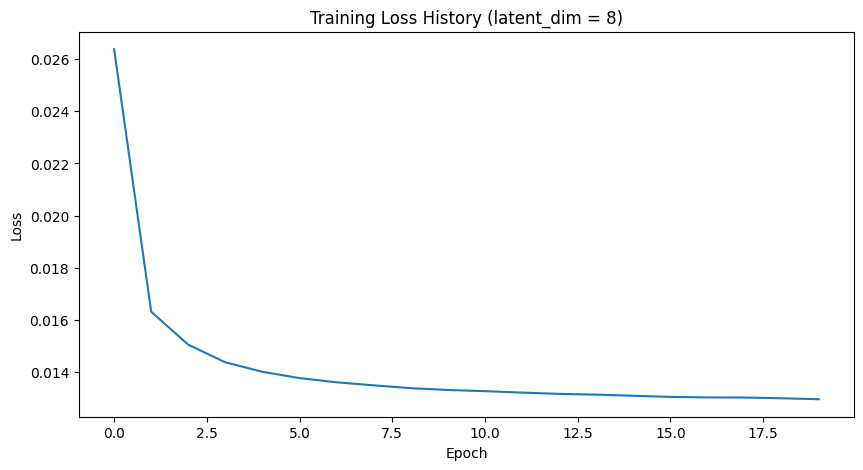

In [3]:
# Train the autoencoder
import matplotlib.pyplot as plt

LATENT_DIM = 8   # size of the bottleneck; try 8, 16, 32


device = 'cpu' if torch.cuda.is_available() else 'mps'

model = Autoencoder(latent_dim=LATENT_DIM).to(device)
optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)
criterion = nn.MSELoss()

loss_hist = []

model.train()
for epoch in range(20):
    running_loss = 0.0
    for data, _ in train_loader:
        data = data.to(device)
        optimizer.zero_grad()
        output = model(data)
        loss = criterion(output, data)
        loss.backward()
        optimizer.step()
        running_loss += loss.item() * data.size(0)  # sum of per-image loss in this batch

    epoch_loss = running_loss / len(train_loader.dataset)  # average loss per image
    loss_hist.append(epoch_loss)

    if epoch % 2 == 0:
        print(f"Epoch {epoch}, Loss: {epoch_loss:.5f}")

# plot the loss history
plt.figure(figsize=(10,5))
plt.plot(loss_hist)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title(f"Training Loss History (latent_dim = {LATENT_DIM})")
plt.show()

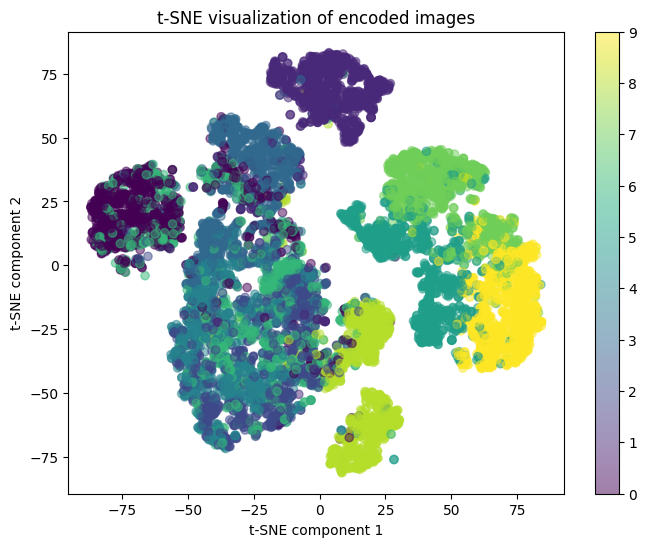

In [7]:
# Encode images into latent space and visualize with tsne
import numpy as np
from sklearn.manifold import TSNE

encoded_imgs = []
labels = []

model.eval()
with torch.no_grad():
    for data, label in test_loader:
        data = data.to(device)
        encoded = model.encoder(data)
        encoded = encoded.view(encoded.size(0), -1)  # flatten
        encoded_imgs.append(encoded.cpu().numpy())
        labels.append(label.numpy())

encoded_imgs = np.concatenate(encoded_imgs, axis=0)
labels = np.concatenate(labels, axis=0)

# Apply t-SNE (play with the parameters till you get a nice plot)
tsne = TSNE(n_components=2, 
    random_state=42, 
    early_exaggeration=12, 
    perplexity=30,
    learning_rate='auto',
    )

encoded_imgs_2d = tsne.fit_transform(encoded_imgs)

plt.figure(figsize=(8, 6))
scatter = plt.scatter(encoded_imgs_2d[:, 0], encoded_imgs_2d[:, 1], c=labels, cmap='viridis', alpha=0.5)
plt.title("t-SNE visualization of encoded images")
plt.xlabel("t-SNE component 1")
plt.ylabel("t-SNE component 2")
plt.colorbar(scatter)
plt.show()

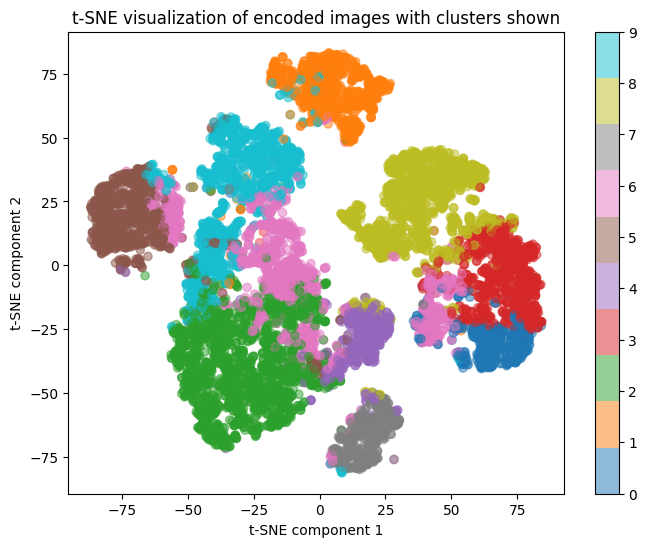

In [8]:
# Perform a clustering method to get your own labels (imagine that we do not know the correct ones)

from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()
encoded_imgs_scaled = scaler.fit_transform(encoded_imgs)

kmeans = KMeans(n_clusters=10, n_init=10, random_state=42)
clusters = kmeans.fit_predict(encoded_imgs_scaled)   # one cluster label per test image, shape (10000,)


plt.figure(figsize=(8, 6))
scatter = plt.scatter(encoded_imgs_2d[:, 0], encoded_imgs_2d[:, 1], c=clusters, cmap='tab10', alpha=0.5)
plt.title("t-SNE visualization of encoded images with clusters shown")
plt.xlabel("t-SNE component 1")
plt.ylabel("t-SNE component 2")
plt.colorbar(scatter, ticks=range(10))
plt.show()

In [9]:
# ! personal added


# Evaluate K-means clusters against the true labels (labels used only for evaluation)
import numpy as np
import pandas as pd
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

class_names = ['T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
               'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot']

# Contingency table: rows = K-means cluster, columns = true class, values = number of images
table = pd.crosstab(pd.Series(clusters, name='Cluster'),
                    pd.Series([class_names[l] for l in labels], name='True class'))
table = table.reindex(columns=class_names, fill_value=0)
print("Images per cluster and true class:")
print(table)
print()

# Majority class of each cluster
majority_class = table.idxmax(axis=1)
majority_share = table.max(axis=1) / table.sum(axis=1)
summary = pd.DataFrame({'Majority class': majority_class,
                        'Share of cluster': majority_share.round(3),
                        'Cluster size': table.sum(axis=1)})
print("Majority class per cluster:")
print(summary)
print()

# Overall scores
purity = table.max(axis=1).sum() / len(labels)
ari = adjusted_rand_score(labels, clusters)
nmi = normalized_mutual_info_score(labels, clusters)
print(f"Purity: {purity:.4f}")
print(f"ARI:    {ari:.4f}")
print(f"NMI:    {nmi:.4f}")

# purity 白話：每一群都看「裡面最多的是哪個真實類別」，就當這群是那個類別，然後算有多少比例的圖被分對。這最接近你想的「準確率」。缺點是兩群可以同時被對到同一個類別，例如兩群都是 Sneaker。
# 2. ARI（Adjusted Rand Index）：看任兩張圖「在分群裡是否同群」跟「在真實標籤裡是否同類」的一致程度，並扣掉隨機分群也會碰巧對到的部分。1 是完全一致，0 是跟隨機分沒兩樣。
# 3. NMI（Normalized Mutual Information）：知道一張圖的 cluster 編號後，能減少多少對它真實類別的不確定性。0 是完全沒幫助，1 是知道 cluster 就完全確定類別。

# ARI 和 NMI 都不用管編號怎麼對應，所以比較常用在學術比較。但最有用的其實是對照表：每一群裡各有多少張屬於哪個真實類別，一眼就看得出哪些類別混在一起。


# Purity: 0.556
# ARI 0.40
# NMI 0.57

# Purity: 0.6051
# ARI:    0.4175
# NMI:    0.5917

# Purity: 0.5565
# ARI:    0.3894
# NMI:    0.5688

Images per cluster and true class:
True class  T-shirt/top  Trouser  Pullover  Dress  Coat  Sandal  Shirt  \
Cluster                                                                  
0                     0        0         0      1     0      79      0   
1                     4      876         0      8     6       0      4   
2                    11       19       765     15   740       0    366   
3                     0        0         0      0     0      88      0   
4                     8        1        13      3     8       0     31   
5                   644        0        14     43     4       0    167   
6                   201       18       195    134    94     307    307   
7                     6        0         1      3     6       3      4   
8                     0        0         0      0     0     520      3   
9                   126       86        12    793   142       3    118   

True class  Sneaker  Bag  Ankle boot  
Cluster                              

GMM converged: True
Average probability of the assigned cluster: 0.930


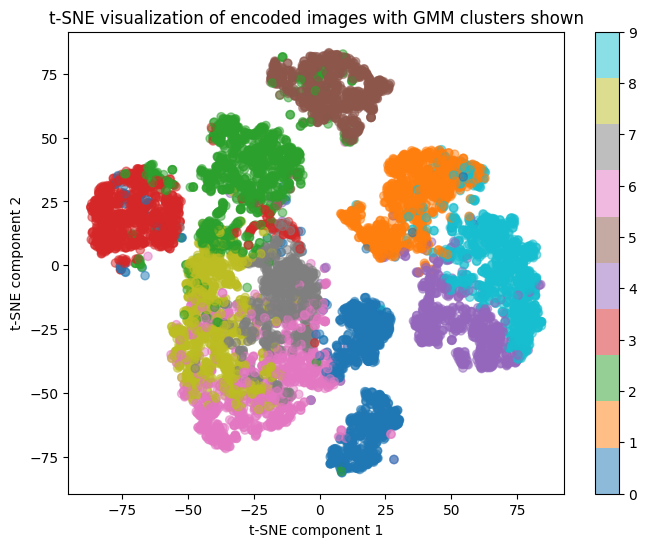

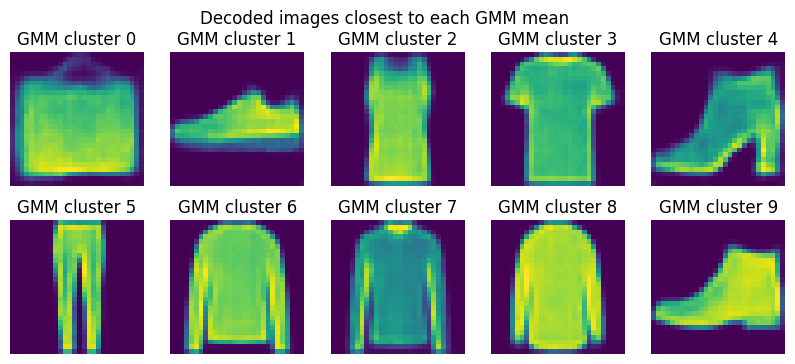

         Purity     ARI     NMI
K-means  0.6015  0.4143  0.5798
GMM      0.6476  0.4736  0.6190


In [11]:
# Cluster the latent vectors with a Gaussian Mixture Model (GMM) and compare with K-means
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.mixture import GaussianMixture
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# 1. Fit GMM on the same standardized latent vectors used for K-means
gmm = GaussianMixture(n_components=10, covariance_type='full', n_init=3, random_state=42)
gmm_clusters = gmm.fit_predict(encoded_imgs_scaled)        # one cluster label per test image, shape (10000,)
gmm_probs = gmm.predict_proba(encoded_imgs_scaled)         # probability of each image belonging to each cluster, shape (10000, 10)

print(f"GMM converged: {gmm.converged_}")
print(f"Average probability of the assigned cluster: {gmm_probs.max(axis=1).mean():.3f}")

# 2. Show the GMM cluster labels on the t-SNE map
plt.figure(figsize=(8, 6))
scatter = plt.scatter(encoded_imgs_2d[:, 0], encoded_imgs_2d[:, 1], c=gmm_clusters, cmap='tab10', alpha=0.5)
plt.title("t-SNE visualization of encoded images with GMM clusters shown")
plt.xlabel("t-SNE component 1")
plt.ylabel("t-SNE component 2")
plt.colorbar(scatter, ticks=range(10))
plt.show()

# 3. Decode the real image closest to each GMM mean (compare in the standardized space)
gmm_means = gmm.means_   # shape (10, latent_dim), in the standardized space

closest_imgs_gmm = []
for mean in gmm_means:
    distances = np.linalg.norm(encoded_imgs_scaled - mean, axis=1)
    closest_imgs_gmm.append(np.argmin(distances))

decoded_images_gmm = []
model.eval()
with torch.no_grad():
    for idx in closest_imgs_gmm:
        encoded_img = torch.tensor(encoded_imgs[idx], dtype=torch.float32).to(device).view(1, -1)  # original (unscaled) latent vector
        decoded_images_gmm.append(model.decoder(encoded_img).cpu().numpy()[0])

fig, axs = plt.subplots(2, 5, figsize=(10, 4))
for i in range(10):
    ax = axs[i//5, i%5]
    ax.imshow(np.transpose(decoded_images_gmm[i], (1, 2, 0)))
    ax.set_title(f"GMM cluster {i}")
    ax.axis('off')
plt.suptitle("Decoded images closest to each GMM mean")
plt.show()

# 4. Compare K-means and GMM against the true labels
def purity_score(true_labels, cluster_labels):
    table = pd.crosstab(cluster_labels, true_labels)
    return table.max(axis=1).sum() / len(true_labels)

results = pd.DataFrame({
    'Purity': [purity_score(labels, clusters), purity_score(labels, gmm_clusters)],
    'ARI':    [adjusted_rand_score(labels, clusters), adjusted_rand_score(labels, gmm_clusters)],
    'NMI':    [normalized_mutual_info_score(labels, clusters), normalized_mutual_info_score(labels, gmm_clusters)],
}, index=['K-means', 'GMM'])

print(results.round(4))

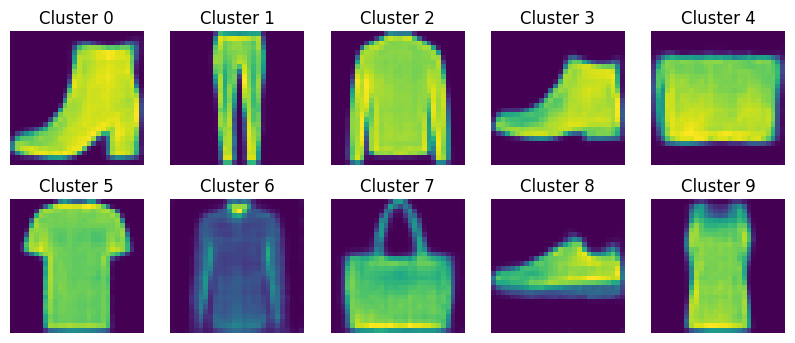

In [10]:
# View centroids of clusters

# View centroids of clusters
import numpy as np
import torch
import matplotlib.pyplot as plt

centroids = kmeans.cluster_centers_   # shape (10, latent_dim), in the standardized space

# find the closest encoded image to each centroid (compare in the standardized space)
closest_imgs = []
for centroid in centroids:
    distances = np.linalg.norm(encoded_imgs_scaled - centroid, axis=1)
    closest_idx = np.argmin(distances)
    closest_imgs.append(closest_idx)

# map the images back to original space
decoded_images = []
for i in range(len(closest_imgs)):
    idx = closest_imgs[i]
    encoded_img = torch.tensor(encoded_imgs[idx], dtype=torch.float32).to(device)  # original (unscaled) latent vector
    encoded_img = encoded_img.view(1, -1)  # reshape to (1, latent_dim) to match our encoder output
    with torch.no_grad():
        decoded_img = model.decoder(encoded_img).cpu().numpy()
    decoded_images.append(decoded_img[0])

# Visualize the decoded images
fig, axs = plt.subplots(2, 5, figsize=(10, 4))
for i in range(10):
    ax = axs[i//5, i%5]
    ax.imshow(np.transpose(decoded_images[i], (1, 2, 0)))
    ax.set_title(f"Cluster {i}")
    ax.axis('off')
# ================================================================================================
# import numpy as np
# import torch
# import matplotlib.pyplot as plt

# centroids = kmeans.cluster_centers_   # shape (10, 16): one 16-dim center per cluster

# # find the closest encoded image to each centroid
# closest_imgs = []
# for centroid in centroids:
#     distances = np.linalg.norm(encoded_imgs - centroid, axis=1)
#     closest_idx = np.argmin(distances)
#     closest_imgs.append(closest_idx)

# # map the images back to original space
# decoded_images = []
# for i in range(len(closest_imgs)):
#     idx = closest_imgs[i]
#     encoded_img = torch.tensor(encoded_imgs[idx], dtype=torch.float32).to(device)
#     encoded_img = encoded_img.view(1, -1)  # reshape to (1, latent_dim) to match our encoder output
#     with torch.no_grad():
#         decoded_img = model.decoder(encoded_img).cpu().numpy()
#     decoded_images.append(decoded_img[0])

# # Visualize the decoded images
# fig, axs = plt.subplots(2, 5, figsize=(10, 4))
# for i in range(10):
#     ax = axs[i//5, i%5]
#     ax.imshow(np.transpose(decoded_images[i], (1, 2, 0)))
#     ax.set_title(f"Cluster {i}")
#     ax.axis('off')
# ================================================================================================

# # View centroids of clusters
# centroids = 

# # find the closest encoded image to each centroid
# closest_imgs = []
# for centroid in centroids:
#     distances = np.linalg.norm(encoded_imgs - centroid, axis=1)
#     closest_idx = np.argmin(distances)
#     closest_imgs.append(closest_idx)

# # map the images back to original space
# decoded_images = []
# for i in range(len(closest_imgs)):
#     idx = closest_imgs[i]
#     encoded_img = torch.tensor(encoded_imgs[idx], dtype=torch.float32).to(device)
#     encoded_img = encoded_img.view(1, 32, 7, 7)  # reshape to match encoder output
#     with torch.no_grad():
#         decoded_img = model.decoder(encoded_img).cpu().numpy()
#     decoded_images.append(decoded_img[0])

# # Visualize the decoded images
# fig, axs = plt.subplots(2, 5, figsize=(10, 4))
# for i in range(10):
#     ax = axs[i//5, i%5]
#     ax.imshow(np.transpose(decoded_images[i], (1, 2, 0)))
#     ax.set_title(f"Cluster {i}")
#     ax.axis('off')

t-SNE coordinates of img1: [  0.67697424 -82.42812   ]
t-SNE coordinates of img2: [ 13.085077 -71.82391 ]


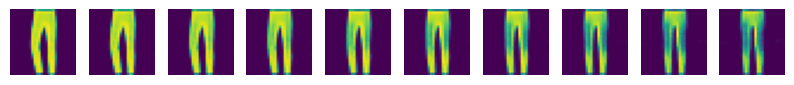

In [11]:
# function for interpolating between two images in the dataset based on their latent representations
def interpolate_images(img1, img2, model, steps=10):
    model.eval()
    with torch.no_grad():
        encoded1 = model.encoder(img1.to(device)).view(1, -1)
        encoded2 = model.encoder(img2.to(device)).view(1, -1)
        
        interpolated_images = []
        for alpha in np.linspace(0, 1, steps):
            interpolated = (1 - alpha) * encoded1 + alpha * encoded2
            # interpolated = interpolated.view(1, 32, 7, 7)  # reshape to match encoder output
            interpolated = interpolated.view(1, -1)  # reshape to (1, latent_dim) to match our encoder output

            decoded_img = model.decoder(interpolated).cpu().numpy()
            interpolated_images.append(decoded_img[0])
    
    fig, axes = plt.subplots(1, steps, figsize=(10, 3))
    for i in range(steps):
        axes[i].imshow(np.transpose(interpolated_images[i], (1, 2, 0)))
        axes[i].axis('off')
    plt.show()
    pass

# Example usage (use your cluster labels to pick two images that are far apart):
img_idx1, img_idx2 = 2, 3

img1, _ = test_data[img_idx1]
img2, _ = test_data[img_idx2]

#print the t-sne coordinates of the two images for reference
print("t-SNE coordinates of img1:", tsne.embedding_[img_idx1])
print("t-SNE coordinates of img2:", tsne.embedding_[img_idx2])

interpolate_images(img1.unsqueeze(0), img2.unsqueeze(0), model, steps=10)

---
## Exercise 2: Anomaly Detection with Autoencoders
This exercise focuses on using autoencoders for anomaly detection. You will train a variational autoencoder on normal data and then use it to identify anomalies based on reconstruction error.

In [12]:
# Import and preprocess the credit card fraud dataset
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

df = pd.read_csv('/Users/fangsiyu/Desktop/SDU-2026-fall-code/DL/creditcard.csv') # from Kaggle: https://www.kaggle.com/datasets/whenamancodes/fraud-detection

scaler = StandardScaler()
X = scaler.fit_transform(df.drop(columns=['Class']))
y = df['Class']

# split data into train and test sets with stratification to maintain class distribution (0.17% fraud cases)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
y_test = np.where(y_test==1, -1, 1)
y = np.where(y==1, -1, 1)

In [13]:
# Try a baseline method: Local Outlier Factor
from sklearn.neighbors import LocalOutlierFactor
from sklearn.metrics import roc_curve, auc, classification_report

clf = LocalOutlierFactor(n_neighbors=250, contamination=0.001)
y_pred = clf.fit_predict(X)
y_pred_proba = clf.negative_outlier_factor_

print(classification_report(y, y_pred, target_names=['Fraud', 'Normal']))

base_fpr, base_tpr, _ = roc_curve(y, y_pred_proba)
base_roc_auc = auc(base_fpr, base_tpr)
print(base_roc_auc)

              precision    recall  f1-score   support

       Fraud       0.05      0.03      0.04       492
      Normal       1.00      1.00      1.00    284315

    accuracy                           1.00    284807
   macro avg       0.53      0.51      0.52    284807
weighted avg       1.00      1.00      1.00    284807

0.797211869521224


In [14]:
# Variational Autoencoder for anomaly detection
import torch
import torch.nn as nn

class TVAE(torch.nn.Module):
    def __init__(self, input_size, hidden_size, latent_size):
        super(TVAE, self).__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_size, hidden_size),    # 30 -> hidden_size
            nn.SiLU(),
            nn.Linear(hidden_size, latent_size),   # hidden_size -> latent_size
            nn.SiLU(),
        )

        self.mean_layer = nn.Linear(latent_size, 2)
        self.logvar_layer = nn.Linear(latent_size, 2)

        self.decoder = nn.Sequential(
            nn.Linear(2, latent_size),             # z (2) -> latent_size
            nn.SiLU(),
            nn.Linear(latent_size, hidden_size),   # latent_size -> hidden_size
        
            nn.SiLU(),
            nn.Linear(hidden_size, input_size),    # hidden_size -> 30, no activation (standardized data can be any real number)
        )

    def encode(self, x):
        x = self.encoder(x)
        mean = self.mean_layer(x)
        logvar = self.logvar_layer(x)
        return mean, logvar

    def reparameterization(self, mean, var):
        # 'var' receives the log-variance (log sigma^2) from forward()
        std = torch.exp(0.5 * var)          # sigma = exp(0.5 * log sigma^2)
        eps = torch.randn_like(std)         # epsilon ~ N(0, 1), same shape as std
        z = mean + std * eps
        return z

    def decode(self, x):
        return self.decoder(x)

    def forward(self, x):
        mean, logvar = self.encode(x)
        z = self.reparameterization(mean, logvar)
        x_hat = self.decode(z)
        return x_hat, mean, logvar

In [15]:
# loss function
def loss_function(recon_x, x, mu, logvar, beta=1.0):
    MSE = nn.functional.mse_loss(recon_x, x, reduction='sum')
    KLD = -0.5 * torch.sum(1 + logvar - mu.pow(2) - logvar.exp())
    return MSE + beta * KLD

In [17]:
# Unsupervised training
device = 'cuda' if torch.cuda.is_available() else 'cpu'

model = TVAE(X_train.shape[1], 16, 4).to(device)
criterion = loss_function

optimizer = torch.optim.Adam(model.parameters(), lr=0.001, weight_decay=1e-5)

train_tensor = torch.tensor(X_train, dtype=torch.float32).to(device)
train_loader = torch.utils.data.DataLoader(train_tensor, batch_size=64, shuffle=True)


model.train()
for epoch in range(10):
    running_loss = 0.0
    for data in train_loader:
        optimizer.zero_grad()
        output, mean, logvar = model(data)
        loss = criterion(output, data, mean, logvar, beta=1.0)
        loss.backward()
        optimizer.step()
        running_loss += loss.item()   # loss is already summed over the batch

    epoch_loss = running_loss / len(train_tensor)   # average loss per transaction
    loss_hist.append(epoch_loss)
    print(f"Epoch {epoch+1}, Loss per sample: {epoch_loss:.5f}")

model.eval()


# model.train()
# for epoch in range(10):
#     for data in train_loader:
#         optimizer.zero_grad()
#         output, mean, logvar = model(data)
#         loss = criterion(output, data, mean, logvar, beta=1.0)
#         loss.backward()
#         optimizer.step()
#     print(f"Epoch {epoch+1}, Loss: {loss.item()}")

# model.eval()

Epoch 1, Loss per sample: 28.97095
Epoch 2, Loss per sample: 27.94813
Epoch 3, Loss per sample: 27.75081
Epoch 4, Loss per sample: 27.66548
Epoch 5, Loss per sample: 27.60695
Epoch 6, Loss per sample: 27.54642
Epoch 7, Loss per sample: 27.49600
Epoch 8, Loss per sample: 27.46150
Epoch 9, Loss per sample: 27.43949
Epoch 10, Loss per sample: 27.32801


TVAE(
  (encoder): Sequential(
    (0): Linear(in_features=30, out_features=16, bias=True)
    (1): SiLU()
    (2): Linear(in_features=16, out_features=4, bias=True)
    (3): SiLU()
  )
  (mean_layer): Linear(in_features=4, out_features=2, bias=True)
  (logvar_layer): Linear(in_features=4, out_features=2, bias=True)
  (decoder): Sequential(
    (0): Linear(in_features=2, out_features=4, bias=True)
    (1): SiLU()
    (2): Linear(in_features=4, out_features=16, bias=True)
    (3): SiLU()
    (4): Linear(in_features=16, out_features=30, bias=True)
  )
)

In [18]:
# Example how a single sample is encoded
with torch.no_grad():
    mean, logvar = model.encode(torch.tensor(X_test[1], dtype=torch.float32).to(device))

(0.0, 1.0)

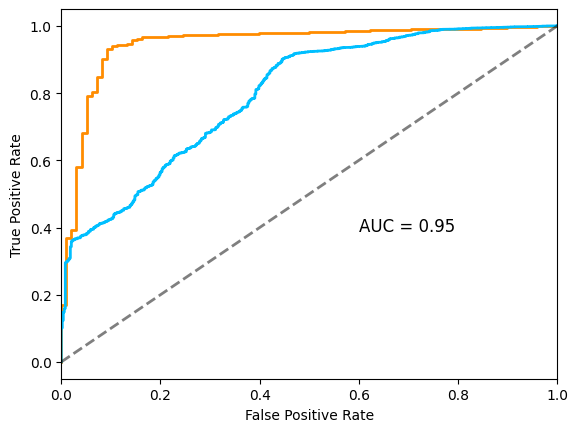

In [19]:
# Calculate reconstruction error and plot ROC curve
import matplotlib.pyplot as plt

with torch.no_grad():
    test_tensor = torch.tensor(X_test, dtype=torch.float32).to(device)
    reconstructed = model(test_tensor)[0].cpu().numpy()
    mse = -np.mean((X_test - reconstructed)**2, axis=1)

fpr, tpr, thresholds = roc_curve(y_test, mse)
roc_auc = auc(fpr, tpr)
plt.figure()
plt.plot(fpr, tpr, color='darkorange', lw=2, label='ROC curve (area = %0.2f)' % roc_auc)
plt.plot(base_fpr, base_tpr, color='deepskyblue', lw=2, label='Baseline ROC curve (area = %0.2f)' % base_roc_auc)
plt.plot([0, 1], [0, 1], color='black', alpha=0.5, lw=2, linestyle='--')
plt.annotate(f'AUC = {roc_auc:.2f}', xy=(0.6, 0.4), xycoords='axes fraction', fontsize=12)
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.xlim([0.0, 1.0])

In [20]:
# choose a threshold based on the percentile of the reconstruction error
threshold = 0.1
y_pred = np.where(mse < np.percentile(mse, threshold), -1, 1)
print(classification_report(y_test, y_pred, target_names=['Fraud', 'Normal']))

              precision    recall  f1-score   support

       Fraud       0.07      0.04      0.05        98
      Normal       1.00      1.00      1.00     56864

    accuracy                           1.00     56962
   macro avg       0.53      0.52      0.53     56962
weighted avg       1.00      1.00      1.00     56962



---

## Exercise 3: De-noising Autoencoder
This exercise aims to recreate the figure from the Alain and Bengio 2013 paper, showing the vector field learned by a de-noising autoencoder.

In [ ]:
# Create a simple 2D spiral dataset
import numpy as np

def generating_function(t):
    return np.array([0.04*t*np.sin(t), 0.04*t*np.cos(t)]).T

t = np.random.uniform(3, 12, 1000)
data = generating_function(t)
data

In [ ]:
# Denoising autoencoder
import torch
import torch.nn as nn

class DenoisingAutoencoder(nn.Module):
    def __init__(self, latent_size=1000, noise_std=0.1):
        super().__init__()
        # Parameters for encoder
        self.b = nn.Parameter(torch.randn(latent_size))
        self.W = nn.Parameter(torch.randn(2,latent_size))

        # Parameters for decoder
        self.c = nn.Parameter(torch.randn(2))
        self.V = nn.Parameter(torch.randn(latent_size,2))

        # Noise standard deviation
        self.noise_std = noise_std
        pass

    def add_noise(self, x):
        x = x.clone()
        ### YOUR CODE HERE
        
        return x 

    def forward(self, x):
        ### YOUR CODE HERE

        return x

In the paper they were using the BFGS optimizer, but here we will use Adam (since it is much faster). 

It took a few tries to get a good result here (i.e. one that behaves well). You may play with the parameters if you find it helpful; e.g., I had to use a considerable amount of epochs (10000). 

[Hint: When the model is in eval mode, the forward pass should not add noise! See lecture 5 for an example of how this can be achieved]

In [ ]:
# Training the denoising autoencoder
device = 'cuda' if torch.cuda.is_available() else 'cpu'

model = DenoisingAutoencoder(
    noise_std=0.01, latent_size=1000).to(device=device)

optimizer = torch.optim.Adam(model.parameters(), lr=0.0001)

loss_fn = 

data_tensor = torch.tensor(data, dtype=torch.float32).to(device)

model.train()
# Training loop
for epoch in range(10000):
    for i in range(0, data_tensor.size(0), 100):
        batch = data_tensor[i:i+100]
        pred = model(batch)
        pred = pred.squeeze()
        loss = loss_fn(pred, batch)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    if epoch % 1000 == 0:
        print(f"Epoch {epoch:<4} | reconstruction loss = {loss.item():.4f}")

In [ ]:
# Visualize how the autoencoder corrects the input
import matplotlib.pyplot as plt

model.eval()

x = torch.linspace(-0.5, 0.5, 31)
y = torch.linspace(-0.5, 0.5, 31)

X, Y = torch.meshgrid(x, y, indexing='ij')
grid_points = torch.stack([X.ravel(), Y.ravel()], dim=-1).to(device)

y = torch.linspace(-0.5, 0.5, 31)

X, Y = torch.meshgrid(x, y, indexing='ij')
grid_points = torch.stack([X.ravel(), Y.ravel()], dim=-1).to(device)

### YOUR CODE HERE: Compute the residuals r(x) - x
with torch.no_grad():
    
    residual =
    
residual = np.multiply(residual, 0.1)  # scale down for better visualization
residual = residual.cpu().numpy()

# Plot the vector field
plt.figure(figsize=(10, 6))
plt.quiver(grid_points[:, 0], grid_points[:, 1],
           residual[:, 0], residual[:, 1],
           angles='xy', scale_units='xy', scale=1, color='r')
plt.plot(data[:, 0], data[:, 1], 'b.', alpha=0.1)  # Plot the original data points
plt.xlim(-0.5, 0.5)
plt.ylim(-0.5, 0.5)
plt.grid(alpha=0.3)
plt.title("De-noising Vector Field")
plt.show()

# Exercise 4: Conditional Generative VAE
This exercise focuses on implementing a Conditional Variational Autoencoder (CVAE) using the digits dataset (you can play around with the MNIST dataset afterwards, but we use digits here since it is faster to train a vaiable model). The goal is to generate images conditioned on specific digit labels.

Notice that we use the flattened versions of the images here, so we do not use any convolutional layers.

In [ ]:
import torch
from torch.utils.data import DataLoader, TensorDataset
from sklearn.datasets import load_digits

# Load and preprocess digits dataset
digits = load_digits()
X = digits.data / 16.0  # Normalize to [0,1]
y = digits.target

# To tensors
X_tensor = torch.FloatTensor(X)
y_tensor = torch.LongTensor(y)

train_dataset = TensorDataset(X_tensor, y_tensor)
train_loader = DataLoader(train_dataset, batch_size=64, shuffle=True)

The primary challenge in building the model compared to what you are used to is to incorporate the labels; my suggestion is that you hold off on the ``nn.Sequential`` API for this exercise. Instead, you can define the layers in the ``__init__`` method and then use them in the respective methods (``encode``, ``decode``, and ``forward``).

I left some hints in the code below, but you will have to fill in the remainder yourself.

In [ ]:
# CVAE Model

# c: labels
# z: latent vector
# mu: mean of the latent distribution
# logvar: log variance of the latent distribution

class CVAE(nn.Module):
    def __init__(self, input_dim, num_classes, latent_dim):
        super(CVAE, self).__init__()
        # Layers for encoder part
        self.enc_fc1 = nn.Linear(input_dim + num_classes,

        # Hint: you need two layers to output mu and logvar

        # Layers for decoder part
        self.dec_fc1 = nn.Linear(latent_dim + num_classes,
                                 
        pass

    def encode(self, x: torch.Tensor, c: torch.Tensor) -> (torch.Tensor, torch.Tensor):
        "Encodes the input by passing through the encoder network and returns the latent codes (mu, logvar)."

        # Hint: You need to concatenate the one-hot encoded labels to the input and latent vectors
        inputs = torch.cat([x, 
        
        
        return mu, logvar

    def reparameterize(self, mu: torch.Tensor, logvar: torch.Tensor) -> torch.Tensor:
        "Reparameterization trick to sample from N(mu, var) from N(0,1)."
        std = torch.exp(0.5 * logvar)
        eps = torch.randn_like(std)
        return mu + eps * std

    def decode(self, z: torch.Tensor, c: torch.Tensor) -> torch.Tensor:
        "Maps the given latent codes onto the image space."
        inputs = torch.cat([z, 
                            

        # Hint: use sigmoid for output (binary-ish colours)                            
        return torch.sigmoid(  

    def forward(self, x: torch.Tensor, c: torch.Tensor) -> (torch.Tensor, torch.Tensor, torch.Tensor):
        "forward pass through the network does both encoding, reparameterization, and decoding"
        mu, logvar = self.encode(x, c)
        z = self.reparameterize(mu, logvar)
        return self.decode(z, c), mu, logvar

    def one_hot(self, labels: torch.Tensor) -> torch.Tensor:
        "Takes a batch of labels and returns their one-hot encoding."

        return 

For the loss function we will use BCE rather than MSE, since the image representations are binary-ish.

In [ ]:
# Loss function
def loss_function(recon_x, x, mu, logvar, beta=1.0):
    BCE = 
    KLD = 
    return BCE + beta * KLD

The new thing here in the training is the beta annealing; you can read more about it in the [beta-VAE paper](https://openreview.net/forum?id=Sy2fzU9gl).
The idea is to start with a small beta and then gradually increase it to 1.0 over the first few epochs. This helps the model to learn a good reconstruction before being forced to learn a good latent representation, there is various ways to do this, but a simple linear increase should be fine.

In [ ]:
# Training
import torch.optim as optim

latent_dim = 10
model = CVAE(input_dim=64, num_classes=10, latent_dim=latent_dim)
optimizer = optim.Adam(model.parameters(), lr=1e-3)

epochs = 100


for epoch in range(epochs):
    model.train()
    train_loss = 0

    # update beta here so that it gradually goes up to 1.0
    beta = 
    for batch_idx, (data, labels) in enumerate(train_loader):
        optimizer.zero_grad()
        recon_batch, mu, logvar = model(data, labels)
        loss = loss_function(recon_batch, data, mu, logvar, beta)
        loss.backward()
        train_loss += loss.item()
        optimizer.step()
        
    print(f'Epoch {epoch+1}, Loss: {train_loss:.4f}, Beta: {beta:.2f}')

In [ ]:
# Visualize generated images for each digit
model.eval()

n_samples = 10
fig, axs = plt.subplots(10, n_samples, figsize=(n_samples, 6))
with torch.no_grad():
    for digit in range(10):
        z = torch.randn(n_samples, latent_dim).to(device)
        c = torch.full((n_samples,), digit, dtype=torch.long).to(device)
        samples = model.decode(z, c)
        generated_imgs = samples.view(n_samples, 8, 8).numpy()
        for i in range(n_samples):
            axs[digit, i].imshow(generated_imgs[i].squeeze(), cmap='gray')
            axs[digit, i].axis('off')

plt.suptitle("Generated Images for Each Digit")
plt.show()

In [ ]:
# Visualize the latent space by fixing one digit and varying the first two dimensions of the latent vector
import numpy as np
import matplotlib.pyplot as plt

model.eval()
n = 10  # Grid size

grid_x = np.linspace(-10, 10, n)    # might need to adjust based on latent space scale
grid_y = np.linspace(-10, 10, n)

digit = 6 # Fixed digit to generate

figure = np.zeros((8 * n, 8 * n))
with torch.no_grad():
    for i, xi in enumerate(grid_x):
        for j, yi in enumerate(grid_y):
            z = torch.tensor([[xi, yi] + [0]*(latent_dim-2)], dtype=torch.float32)  # Fix other dims to 0
            c = torch.tensor([digit], dtype=torch.long)
            sample = model.decode(z, c).view(8, 8).numpy()
            figure[i * 8: (i + 1) * 8,
                   j * 8: (j + 1) * 8] = sample
            
plt.figure(figsize=(10, 10))
plt.imshow(figure, cmap='gray')
plt.axis('off')